## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, **Invasive** means pump and **Conservative** means not.

In [3]:
df = pd.read_csv('iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  291   98
Invasive      294   94 

Estimated ATE:  -0.01


1. -0.01, they are fairly even but more people from the sample survived in the group that did not receive the pump.

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms because that maximizes statistical power)**.

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    ## Resample:
    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    ## Evaluate outcomes:
    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    

    ## Compute ATE:
    ate_t = oat - obt # Compute ATE for this bootstrap sample
    
    ## Store results:
    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

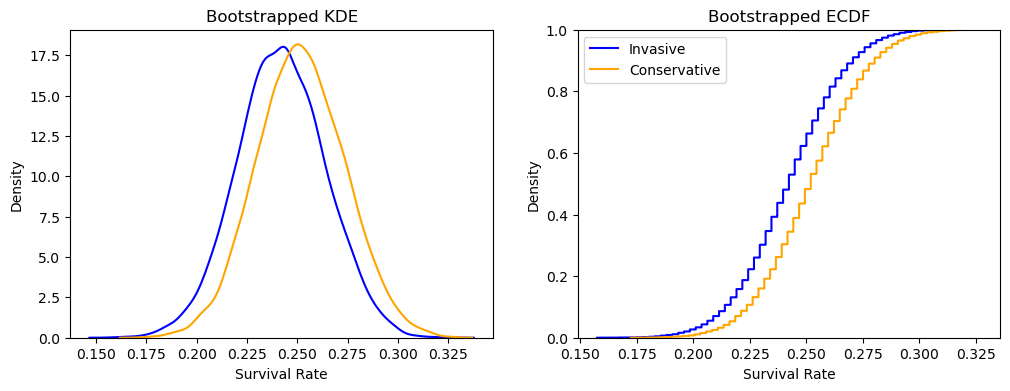

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

Both groups have very similar shaped distributions, but the conservative group is pushed slightly to the right showing that they have better survival odds.

**4.** Make a plot of the KDE and ECDF for the ATE. Does it have a roughly bell shape? What range of values are possible for this intervention?

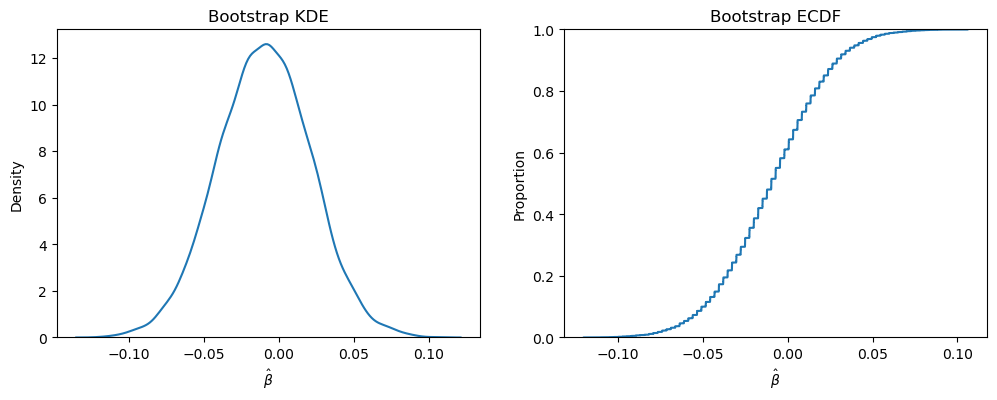

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Yes it is bell shaped. The range of possible values are approximately -0.10 to 0.08.

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [6]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06112057  0.04180691]
95% CI: [-0.07139656  0.05207643]
99% CI: [-0.08693322  0.0700913 ]


We fail to reject the null hypothesis that the effect size is 0 for all 3 since 0 is contained in our intervals.

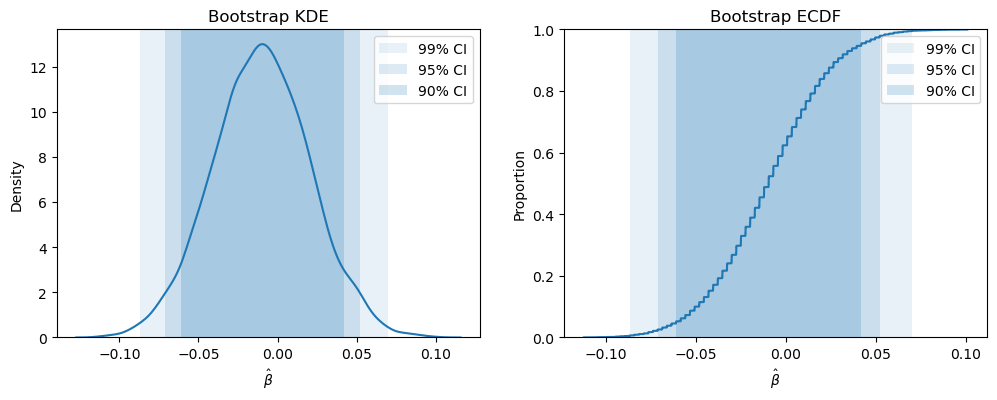

In [7]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

Each interval reaches further below zero than above it and the center is slightly negative.

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

In [6]:
## Loading diabetes dataset and CrossTab
import pandas as pd
diabetes = pd.read_csv('diabetes.csv')


diabetes['success'] = (diabetes['outcome'] == 'success').astype(int)


print(pd.crosstab(diabetes['treatment'], diabetes['outcome']), '\n')


print(diabetes.groupby('treatment')['success'].mean().round(3))


outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: success, dtype: float64


In [7]:
import numpy as np
## Bootstrapping:
R = 10_000

diabetes_met = diabetes.loc[ diabetes['treatment'] == 'met', :]
diabetes_rosi = diabetes.loc[ diabetes['treatment'] == 'rosi', :]
diabetes_life = diabetes.loc[ diabetes['treatment'] == 'lifestyle', :]

outcome_met = []
outcome_rosi = []
outcome_life = []

for t in range(R):
    ## Resample within each arm:
    diabetes_met_t = diabetes_met.sample(frac=1.0, replace=True)
    diabetes_rosi_t = diabetes_rosi.sample(frac=1.0, replace=True)
    diabetes_life_t = diabetes_life.sample(frac=1.0, replace=True)

    ## Evaluate outcomes and store results:
    outcome_met.append(diabetes_met_t['success'].mean())
    outcome_rosi.append(diabetes_rosi_t['success'].mean())
    outcome_life.append(diabetes_life_t['success'].mean())

outcome_met = np.array(outcome_met)
outcome_rosi = np.array(outcome_rosi)
outcome_life = np.array(outcome_life)

## Pairwise ATEs (used in Q4–5):
ate_met_rosi = outcome_met - outcome_rosi
ate_met_life = outcome_met - outcome_life
ate_rosi_life = outcome_rosi - outcome_life


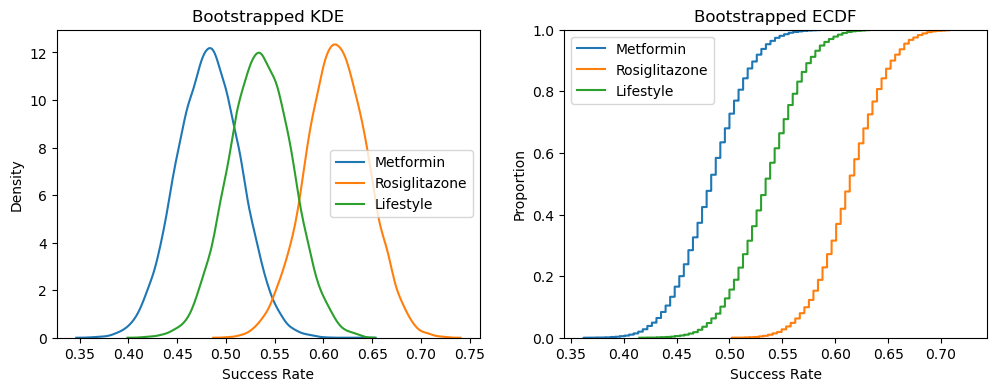

In [10]:
## Desnity Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDEs
sns.kdeplot(outcome_met, label='Metformin', ax=ax[0])
sns.kdeplot(outcome_rosi, label='Rosiglitazone', ax=ax[0])
sns.kdeplot(outcome_life, label='Lifestyle', ax=ax[0])
ax[0].set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')
ax[0].legend()

## ECDFs
sns.ecdfplot(outcome_met, label='Metformin', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='Rosiglitazone', ax=ax[1])
sns.ecdfplot(outcome_life, label='Lifestyle', ax=ax[1])
ax[1].set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Proportion')
ax[1].legend()

plt.show()


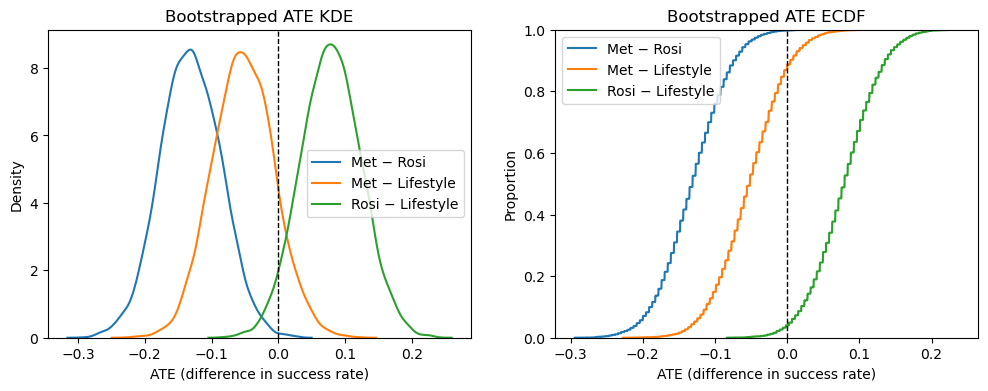

In [11]:

## KDE and ECDF Plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ates = {
    'Met − Rosi': ate_met_rosi,
    'Met − Lifestyle': ate_met_life,
    'Rosi − Lifestyle': ate_rosi_life,
}

for label, a in ates.items():
    sns.kdeplot(a, label=label, ax=ax[0])
    sns.ecdfplot(a, label=label, ax=ax[1])

## Reference line at zero (no effect)
for a_ in ax:
    a_.axvline(0, color='black', linestyle='--', linewidth=1)

ax[0].set(title='Bootstrapped ATE KDE', xlabel='ATE (difference in success rate)', ylabel='Density')
ax[1].set(title='Bootstrapped ATE ECDF', xlabel='ATE (difference in success rate)', ylabel='Proportion')
ax[0].legend()
ax[1].legend()

plt.show()


In [12]:
levels = {'90%': [.05, .95], '95%': [.025, .975], '99%': [.005, .995]}

rows = []
for label, a in ates.items():
    row = {'Comparison': label, 'ATE': np.round(np.mean(a), 3)}
    for lvl, qs in levels.items():
        lo, hi = np.quantile(a, qs)
        row[lvl + ' CI'] = f'[{lo:.3f}, {hi:.3f}]'
    rows.append(row)

ci_table = pd.DataFrame(rows)
print(ci_table.to_string(index=False))


      Comparison    ATE           90% CI           95% CI           99% CI
      Met − Rosi -0.131 [-0.204, -0.058] [-0.221, -0.041] [-0.251, -0.015]
 Met − Lifestyle -0.053  [-0.129, 0.026]  [-0.142, 0.039]  [-0.172, 0.069]
Rosi − Lifestyle  0.079   [0.007, 0.152]  [-0.010, 0.169]  [-0.036, 0.195]
